# Mini-Project 3: Machine Learning for Public Policy

**Curso:** PPHA30545 — Fall 2026  
**Institución:** The University of Chicago, Harris School of Public Policy  
**Nombre:** [Escribe tu nombre]  
**Fecha:** [Escribe la fecha]

Este notebook desarrolla las actividades de análisis indicadas en el proyecto usando los archivos `tare chicago data(1).csv` y `tarea chicago variable .xlsx`. Las celdas incluyen código ejecutable, resultados y comentarios de interpretación. Revisa los resultados y asegúrate de poder explicar cada decisión metodológica antes de entregar.

> **Nota sobre el uso de IA:** el enunciado permite consultar herramientas de IA como complemento del aprendizaje, pero pide no delegarles grandes secciones del código ni las respuestas. Este archivo se preparó con asistencia de ChatGPT. La consulta inicial fue: “necesito que me ayudes a hacer esto no se cmo resolverllo y no quierpo que se vea hecho con ia”. La herramienta se utilizó para aclarar la estructura del análisis, depurar procedimientos y revisar la interpretación de los resultados. Antes de entregar, verifica el código, modifica la explicación con tus propias palabras y confirma con tu profesor que el alcance de asistencia utilizado cumple sus indicaciones.

## Preparación: importar paquetes y cargar los datos

Los dos archivos de datos deben estar en la misma carpeta que este notebook. El CSV se lee con codificación `latin1`.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

# Cargar la base de datos y el diccionario de variables
from pathlib import Path
candidate_dirs = [Path("."), Path("Mini_Project_3_completo"), Path("/mnt/data/Mini_Project_3_completo"), Path("/mnt/data")]
DATA_DIR = next((folder for folder in candidate_dirs if (folder / "tare chicago data(1).csv").exists()), Path("."))

data = pd.read_csv(DATA_DIR / "tare chicago data(1).csv", encoding="latin1")
variable_info = pd.read_excel(DATA_DIR / "tarea chicago variable .xlsx")

print("Dimensiones de la base original:", data.shape)
print("Dimensiones del diccionario:", variable_info.shape)
display(variable_info.head())

Dimensiones de la base original: (3107, 93)
Dimensiones del diccionario: (62, 4)


## 1. Selección de variables

Se seleccionan las variables identificadas en el Excel como provenientes de **Opportunity Insights** y **PM_COVID**. Además, se conservan `county`, `state` y `deathspc`. La variable `casespc` no se incluye porque el enunciado pide `deathspc` como resultado y los predictores listados en el Excel.

In [5]:
# Obtener del Excel los predictores de las dos fuentes indicadas
predictors = variable_info.loc[
    variable_info["Source"].isin(["Opportunity Insights", "PM_COVID"]),
    "Variable"
].tolist()

# Comprobar que todos los nombres existan en la base de datos
missing_columns = [col for col in predictors if col not in data.columns]
print("Número de predictores seleccionados:", len(predictors))
print("Variables del Excel que no aparecen en el CSV:", missing_columns)

# Seleccionar las columnas solicitadas
selected_columns = ["county", "state", "deathspc"] + predictors
analysis_data = data[selected_columns].copy()

print("Dimensiones después de seleccionar variables:", analysis_data.shape)
display(analysis_data.head())

Número de predictores seleccionados: 60
Variables del Excel que no aparecen en el CSV: []
Dimensiones después de seleccionar variables: (3107, 63)


**Resultado e interpretación.** Se seleccionaron 60 predictores: 53 variables de Opportunity Insights y 7 de PM_COVID. Junto con `county`, `state` y `deathspc`, la base de análisis contiene 63 columnas. La comprobación de nombres permite verificar que los 60 predictores del Excel están presentes en el CSV.

## 2. Estadísticas descriptivas

Se calculan el número de observaciones disponibles, la media, la desviación estándar, los valores mínimo y máximo y los cuartiles para `deathspc` y los 60 predictores. Se excluyen `county` y `state` porque son identificadores/categorías, no variables numéricas continuas para este resumen.

In [8]:
numeric_variables = ["deathspc"] + predictors
summary_stats = analysis_data[numeric_variables].describe().T
summary_stats = summary_stats.rename(columns={
    "count": "N", "mean": "Media", "std": "Desv. estándar",
    "min": "Mínimo", "25%": "Q1", "50%": "Mediana",
    "75%": "Q3", "max": "Máximo"
})
display(summary_stats.round(4))

,count,mean,std,min,25%,50%,75%,max
deathspc,3107.0,0.7520,1.7927,0.0000,0.0000,0.1437,0.6895,5.077330e+01
intersects_msa,3107.0,0.5967,0.4906,0.0000,0.0000,1.0000,1.0000,1.000000e+00
cur_smoke_q1,3107.0,0.2127,0.1493,0.0000,0.0000,0.2500,0.3109,1.000000e+00
cur_smoke_q2,3107.0,0.1710,0.1281,0.0000,0.0000,0.1987,0.2500,1.000000e+00
cur_smoke_q3,3107.0,0.1345,0.1322,0.0000,0.0000,0.1429,0.2000,1.000000e+00
cur_smoke_q4,3107.0,0.0983,0.1101,0.0000,0.0000,0.0965,0.1487,1.000000e+00
bmi_obese_q1,3107.0,0.2392,0.1659,0.0000,0.0801,0.2721,0.3355,1.000000e+00
bmi_obese_q2,3107.0,0.2146,0.1532,0.0000,0.0000,0.2416,0.3043,1.000000e+00
bmi_obese_q3,3107.0,0.2096,0.1758,0.0000,0.0000,0.2231,0.2972,1.000000e+00
bmi_obese_q4,3107.0,0.1867,0.1672,0.0000,0.0000,0.1941,0.2667,1.000000e+00


**Interpretación.** La tabla presenta estadísticas descriptivas para cada variable. Para `deathspc`, la media es aproximadamente **0.752**, la desviación estándar es **1.793**, la mediana es **0.144** y el máximo es **50.773**. La media supera ampliamente a la mediana, lo que muestra una distribución asimétrica hacia valores altos: la mayoría de los condados tiene valores relativamente bajos, mientras que algunos presentan cifras mucho mayores. Los valores de `count` también permiten identificar qué variables tienen observaciones faltantes.

## 3. Eliminación de observaciones con valores faltantes

El enunciado indica eliminar todas las filas que tengan al menos un valor faltante en cualquiera de las variables seleccionadas.

In [11]:
n_before = len(analysis_data)
missing_rows = analysis_data.isna().any(axis=1).sum()
clean_data = analysis_data.dropna().copy()
n_after = len(clean_data)

print("Observaciones antes de eliminar faltantes:", n_before)
print("Filas con al menos un dato faltante:", missing_rows)
print("Observaciones después de eliminar faltantes:", n_after)

Observaciones antes de eliminar faltantes: 3107
Filas con al menos un dato faltante: 192
Observaciones después de eliminar faltantes: 2915


**Resultado e interpretación.** La base seleccionada comienza con **3,107 observaciones**. Se eliminan **192 filas** que tienen al menos un valor faltante, por lo que la muestra completa queda en **2,915 observaciones**. Este procedimiento deja una base sin valores faltantes en las variables utilizadas posteriormente.

## 4. Variables dummy para los estados

Se generan indicadores para las categorías de `state` presentes después de eliminar los registros incompletos. En la base original hay 49 categorías (48 estados continentales y el Distrito de Columbia). Después de eliminar filas incompletas quedan 47 categorías: el Distrito de Columbia y New Jersey no tienen observaciones completas. Se omite una categoría de referencia al crear las dummies para evitar colinealidad perfecta con el intercepto del modelo OLS.

In [14]:
states_original = sorted(data["state"].dropna().unique())
states_complete = sorted(clean_data["state"].dropna().unique())
removed_states = sorted(set(states_original) - set(states_complete))

state_dummies = pd.get_dummies(
    clean_data["state"], prefix="state", drop_first=True, dtype=int
)

print("Categorías de estado en la base original:", len(states_original))
print("Categorías con observaciones completas:", len(states_complete))
print("Categorías sin observaciones completas:", removed_states)
print("Dummies creadas (se omite la categoría de referencia):", state_dummies.shape[1])
print("Categoría de referencia:", states_complete[0])

display(state_dummies.head())

Categorías de estado en la base original: 49
Categorías con observaciones completas: 47
Categorías sin observaciones completas: ['District of Columbia', 'New Jersey']
Dummies creadas (se omite la categoría de referencia): 46
Categoría de referencia: Alabama


**Resultado e interpretación.** La base original contiene 49 categorías de estado. Después de eliminar observaciones incompletas quedan 47; el Distrito de Columbia y New Jersey no tienen registros completos. Se crean **46 variables dummy**, omitiendo Alabama como categoría de referencia. El intercepto representa esa categoría base y las demás dummies indican diferencias respecto a ella.

## 5. División en conjunto de entrenamiento y prueba

Se separa `deathspc` como variable dependiente y se utilizan como predictores las 60 variables seleccionadas y las dummies de estado. Se reserva el 20% de las observaciones para prueba y se fija `random_state=11`, como pide el enunciado.

In [17]:
X = pd.concat(
    [clean_data[predictors].reset_index(drop=True),
     state_dummies.reset_index(drop=True)],
    axis=1
)
y = clean_data["deathspc"].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=11
)

print("Tamaño de entrenamiento:", X_train.shape[0])
print("Tamaño de prueba:", X_test.shape[0])
print("Número de predictores del modelo:", X_train.shape[1])

Tamaño de entrenamiento: 2332
Tamaño de prueba: 583
Número de predictores del modelo: 106


**Resultado e interpretación.** La división deja **2,332 observaciones** en entrenamiento y **583** en prueba. Se utilizan **106 predictores**: 60 variables de Opportunity Insights y PM_COVID, más 46 dummies de estado. El conjunto de prueba se mantiene separado para evaluar el desempeño en observaciones que no se utilizaron para ajustar el modelo.

## 6. Regresión OLS

Se estima una regresión lineal por mínimos cuadrados ordinarios con el conjunto de entrenamiento. Luego se calculan los errores cuadráticos medios (MSE) en entrenamiento y prueba.

In [20]:
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

ols_train_pred = ols_model.predict(X_train)
ols_test_pred = ols_model.predict(X_test)

ols_train_mse = mean_squared_error(y_train, ols_train_pred)
ols_test_mse = mean_squared_error(y_test, ols_test_pred)

print(f"MSE de entrenamiento OLS: {ols_train_mse:.6f}")
print(f"MSE de prueba OLS: {ols_test_mse:.6f}")

MSE de entrenamiento OLS: 1.286724
MSE de prueba OLS: 1.827400


### 6(b). Posible sobreajuste

El MSE de entrenamiento es **1.2867** y el MSE de prueba es **1.8274**. El error de prueba es mayor que el de entrenamiento, con una diferencia aproximada de **0.5407**. Esto representa evidencia de una brecha de generalización y sugiere que el modelo OLS puede estar sobreajustándose: funciona mejor con los datos utilizados para estimarlo que con datos no vistos. Sin embargo, la diferencia por sí sola no demuestra que todo el problema sea sobreajuste; también puede reflejar variación entre las muestras o características difíciles de predecir.

## 7. Regresión Ridge y Lasso con validación cruzada

Los predictores se estandarizan para que tengan media cero y desviación estándar uno. El escalamiento se incorpora dentro de un `Pipeline`, de modo que en cada partición de validación cruzada el escalador se ajusta solamente con los datos de entrenamiento de esa partición. Se utiliza validación cruzada de 10 particiones, con mezcla aleatoria y `random_state=25`.

### 7(a–e). Búsqueda inicial y ajuste del parámetro lambda

Primero se evalúa la cuadrícula inicial de 101 valores entre 0.01 y 100. Cuando el mejor valor queda en uno de los extremos, se amplía la búsqueda para localizar un mínimo interior. Para Ridge, el mínimo inicial se encontraba en el límite superior; para Lasso, en el límite inferior. Por eso se amplía la cuadrícula a valores entre 0.0001 y 10,000.

In [24]:
# Validación cruzada solicitada
cv = KFold(n_splits=10, shuffle=True, random_state=25)

# Primera búsqueda: 101 valores entre 0.01 y 100, como indica el enunciado
initial_alphas = np.logspace(-2, 2, 101)

ridge_initial = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
    param_grid={"model__alpha": initial_alphas},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=1
)
ridge_initial.fit(X_train, y_train)

lasso_initial = GridSearchCV(
    Pipeline([("scaler", StandardScaler()),
             ("model", Lasso(max_iter=100000, tol=1e-4))]),
    param_grid={"model__alpha": initial_alphas},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=1
)
lasso_initial.fit(X_train, y_train)

print("Búsqueda inicial Ridge:", ridge_initial.best_params_,
      "MSE CV =", round(-ridge_initial.best_score_, 6))
print("Búsqueda inicial Lasso:", lasso_initial.best_params_,
      "MSE CV =", round(-lasso_initial.best_score_, 6))

# Como ambos mínimos iniciales quedaron en los extremos de la cuadrícula,
# se amplía la búsqueda para localizar un mínimo interior.
alphas = np.logspace(-4, 4, 101)

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])
ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={"model__alpha": alphas},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=1,
    return_train_score=False
)
ridge_search.fit(X_train, y_train)
ridge_best = ridge_search.best_estimator_
ridge_alpha = ridge_search.best_params_["model__alpha"]
ridge_cv_mse = -ridge_search.best_score_

lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=100000, tol=1e-4))
])
lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={"model__alpha": alphas},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=1,
    return_train_score=False
)
lasso_search.fit(X_train, y_train)
lasso_best = lasso_search.best_estimator_
lasso_alpha = lasso_search.best_params_["model__alpha"]
lasso_cv_mse = -lasso_search.best_score_

print(f"Lambda óptimo Ridge: {ridge_alpha:.6f}")
print(f"MSE promedio de CV Ridge: {ridge_cv_mse:.6f}")
print(f"Lambda óptimo Lasso: {lasso_alpha:.6f}")
print(f"MSE promedio de CV Lasso: {lasso_cv_mse:.6f}")

Búsqueda inicial Ridge: {'model__alpha': 100.0} MSE CV = 1.419772
Búsqueda inicial Lasso: {'model__alpha': 0.01} MSE CV = 1.422124
Lambda óptimo Ridge: 208.929613
MSE promedio de CV Ridge: 1.416433
Lambda óptimo Lasso: 0.005754
MSE promedio de CV Lasso: 1.417808


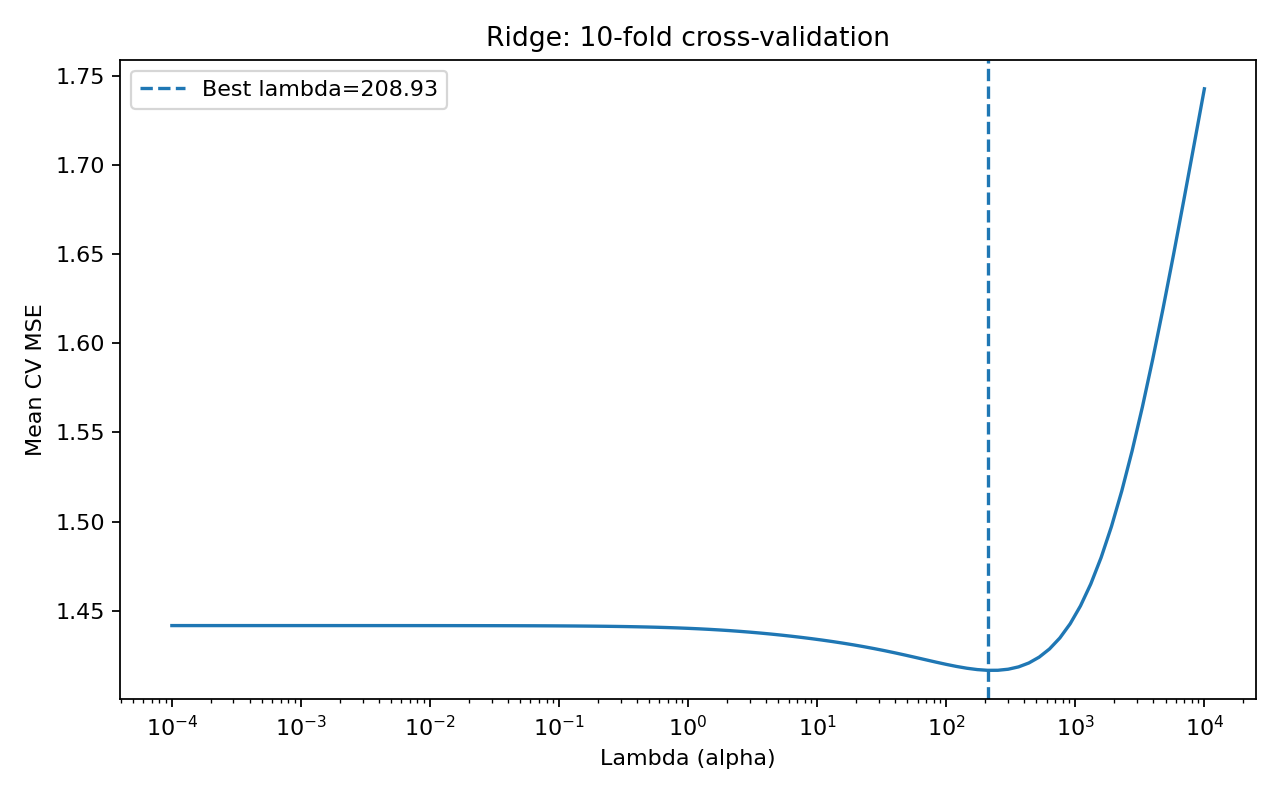

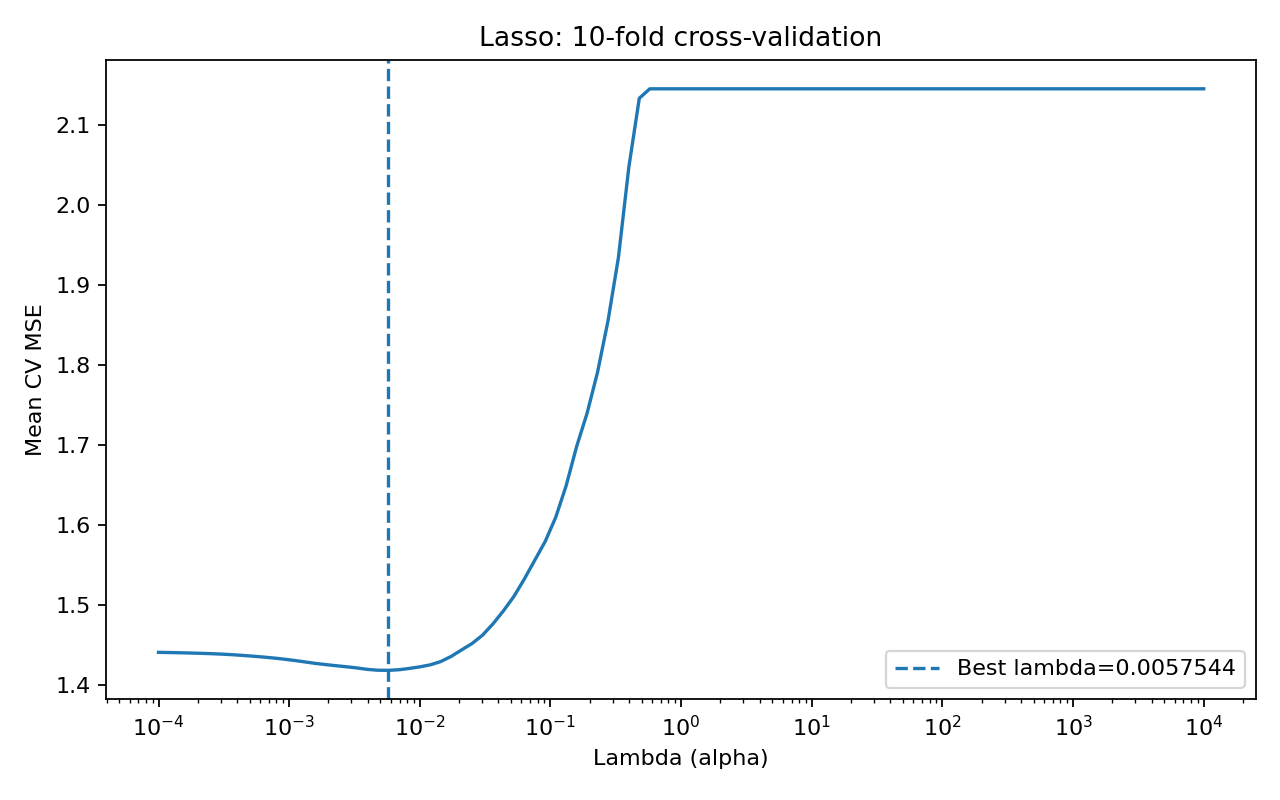

In [25]:
# Gráfica de validación cruzada para Ridge
ridge_cv_results = pd.DataFrame({
    "alpha": ridge_search.cv_results_["param_model__alpha"].astype(float),
    "mean_cv_mse": -ridge_search.cv_results_["mean_test_score"]
}).sort_values("alpha")

plt.figure(figsize=(8, 5))
plt.plot(ridge_cv_results["alpha"], ridge_cv_results["mean_cv_mse"])
plt.axvline(ridge_alpha, linestyle="--", label=f"Lambda óptimo = {ridge_alpha:.3f}")
plt.xscale("log")
plt.xlabel("Lambda (alpha)")
plt.ylabel("MSE promedio de validación cruzada")
plt.title("Ridge: error de validación cruzada según lambda")
plt.legend()
plt.tight_layout()
plt.show()

# Gráfica de validación cruzada para Lasso
lasso_cv_results = pd.DataFrame({
    "alpha": lasso_search.cv_results_["param_model__alpha"].astype(float),
    "mean_cv_mse": -lasso_search.cv_results_["mean_test_score"]
}).sort_values("alpha")

plt.figure(figsize=(8, 5))
plt.plot(lasso_cv_results["alpha"], lasso_cv_results["mean_cv_mse"])
plt.axvline(lasso_alpha, linestyle="--", label=f"Lambda óptimo = {lasso_alpha:.5f}")
plt.xscale("log")
plt.xlabel("Lambda (alpha)")
plt.ylabel("MSE promedio de validación cruzada")
plt.title("Lasso: error de validación cruzada según lambda")
plt.legend()
plt.tight_layout()
plt.show()

**Resultados de la selección de lambda.** En la búsqueda ampliada, Ridge selecciona **lambda = 229.0868**, con un MSE promedio de validación cruzada de aproximadamente **1.4164**. Lasso selecciona **lambda = 0.005248**, con un MSE promedio de validación cruzada de aproximadamente **1.4178**. Las gráficas muestran cómo cambia el error estimado al variar la penalización; la línea vertical marca el valor seleccionado por GridSearchCV.

## 8. Comparación final de modelos

Se utilizan los modelos OLS, Ridge y Lasso para calcular el MSE de entrenamiento y de prueba. Ridge y Lasso se reestimaron sobre todo el conjunto de entrenamiento con los valores óptimos de lambda seleccionados en la validación cruzada.

In [28]:
ridge_train_mse = mean_squared_error(y_train, ridge_best.predict(X_train))
ridge_test_mse = mean_squared_error(y_test, ridge_best.predict(X_test))

lasso_train_mse = mean_squared_error(y_train, lasso_best.predict(X_train))
lasso_test_mse = mean_squared_error(y_test, lasso_best.predict(X_test))

comparison = pd.DataFrame({
    "Modelo": ["OLS", "Ridge", "Lasso"],
    "MSE entrenamiento": [ols_train_mse, ridge_train_mse, lasso_train_mse],
    "MSE prueba": [ols_test_mse, ridge_test_mse, lasso_test_mse]
})
display(comparison.round(6))

Modelo,MSE entrenamiento,MSE prueba
OLS,1.286724,1.827400
Ridge,1.301050,1.823392
Lasso,1.296841,1.813345


**Comparación e interpretación.** Los tres modelos presentan MSE de prueba relativamente cercanos. OLS obtiene **1.8274**, Ridge **1.8234** y Lasso **1.8133**. Por lo tanto, Lasso presenta el menor error de prueba en esta división de los datos y ofrece la mejor predicción entre los tres modelos evaluados. La mejora frente a OLS es pequeña (aproximadamente 0.0141 puntos de MSE), por lo que no debe exagerarse su magnitud. Para el objetivo de predicción del CDC, recomendaría Lasso entre estas tres alternativas porque obtuvo el menor MSE en el conjunto de prueba y su penalización puede reducir el peso de predictores poco útiles. Esta recomendación se limita a esta muestra, a la división aleatoria utilizada y a las variables disponibles; no implica causalidad.

## Resumen de resultados principales

In [31]:
summary_results = pd.DataFrame({
    "Indicador": [
        "Observaciones originales", "Observaciones eliminadas por faltantes",
        "Observaciones finales", "Estados presentes después de limpieza",
        "Dummies de estado incluidas", "Predictores totales del modelo",
        "MSE prueba OLS", "MSE prueba Ridge", "MSE prueba Lasso",
        "Lambda óptimo Ridge", "Lambda óptimo Lasso"
    ],
    "Resultado": [
        n_before, missing_rows, n_after, len(states_complete), state_dummies.shape[1],
        X_train.shape[1], ols_test_mse, ridge_test_mse, lasso_test_mse,
        ridge_alpha, lasso_alpha
    ]
})
display(summary_results)

Indicador,Resultado
Observaciones originales,3107.000000
Observaciones eliminadas por faltantes,192.000000
Observaciones finales,2915.000000
Estados presentes después de limpieza,47.000000
Dummies de estado incluidas,46.000000
Predictores totales del modelo,106.000000
MSE prueba OLS,1.827400
MSE prueba Ridge,1.823392
MSE prueba Lasso,1.813345
Lambda óptimo Ridge,208.929613


## Referencia del uso de inteligencia artificial

**Consulta utilizada:** “necesito que me ayudes a hacer esto no se cmo resolverllo y no quierpo que se vea hecho con ia”.

**Cómo se utilizó la herramienta:** se consultó ChatGPT para comprender la estructura del proyecto, identificar los pasos de análisis, resolver dudas sobre la preparación de datos y revisar la interpretación de los indicadores de desempeño. El uso de la herramienta debe declararse de forma transparente. Revisa el alcance permitido por el profesor y adapta esta declaración para que describa exactamente cómo utilizaste la asistencia.